# Praktik 5. Machine Learning untuk Digital Soil Mapping

Notebook ini melanjutkan kovariat yang disiapkan di QGIS, lalu mengikuti persamaan SCORPAN pada Modul 8: mempelajari fungsi yang menghubungkan sifat tanah di titik sampel dengan kondisi lingkungannya, menilai fungsi tersebut secara jujur, lalu menerapkannya ke seluruh piksel Sub-DAS Bompon.

Notebook dibagi menjadi tiga bagian:

- **Bagian A**, Machine Learning untuk DSM;
- **Bagian B**, penyiapan dan pemilihan kovariat berdasarkan SCORPAN;
- **Bagian C**, pembangunan model DSM.

Satu hal perlu dipegang sejak awal: hanya ada 50 titik, sedangkan DEM yang dipakai berasal dari data global 30 m. Jangan menganggap model pasti berhasil hanya karena petanya terlihat meyakinkan. Biarkan angka validasi yang berbicara.

## Menyiapkan lingkungan kerja

In [1]:
import os, sys

# Di Google Colab: pasang pustaka lalu sambungkan Drive. Di Jupyter lokal bagian ini dilewati.
if 'google.colab' in sys.modules:
    !pip -q install numpy pandas scipy scikit-learn matplotlib rasterio quantile-forest
    from google.colab import drive
    drive.mount('/content/drive')
    os.chdir('/content/drive/MyDrive/Pelatihan/data/praktik-5')   # sesuaikan dengan lokasi folder Anda

os.makedirs('hasil', exist_ok=True)
print('Folder kerja:', os.path.basename(os.getcwd()))

Folder kerja: praktik-5


In [2]:
import glob
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import rasterio
from sklearn.cluster import KMeans
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import GroupKFold, KFold, cross_val_predict, train_test_split
from sklearn.neighbors import NearestNeighbors
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from quantile_forest import RandomForestQuantileRegressor
plt.rcParams.update({'figure.dpi': 110, 'font.size': 9})
warnings.filterwarnings('ignore', category=UserWarning)

# Bagian A. Machine Learning untuk DSM

## A1. Membaca data sampel dan kovariat

Berkas `sampel_tanah_bompon.csv` memuat hasil laboratorium 50 titik pada dua kedalaman. Akhiran `_1` berarti 0–20 cm dan `_2` berarti 20–40 cm. Folder `kovariat/` berisi satu GeoTIFF untuk setiap kovariat, semuanya pada grid 10 m yang sama.

In [3]:
sampel = pd.read_csv('sampel_tanah_bompon.csv')
jalur = sorted(glob.glob('kovariat/*.tif'))
nama_kov = [os.path.basename(p)[:-4] for p in jalur]
susunan = []
for p in jalur:
    with rasterio.open(p) as r:
        susunan.append(r.read(1))
        transform, crs, tinggi, lebar = r.transform, r.crs, r.height, r.width
kubus = np.stack(susunan)      # kovariat x baris x kolom
print('Titik sampel :', len(sampel))
print('Kovariat     :', len(nama_kov), nama_kov)
print('Ukuran grid  :', kubus.shape[1:], '| CRS', crs)
sampel[['Titik', 'x', 'y', 'C_Organik_1', 'C_Organik_2', 'Bahan_Organik_1', 'Bahan_Organik_2', 'Lempung_1', 'pH_H2O_1', 'KPK_1']].describe().T[['count', 'min', 'mean', 'max', 'std']].round(2)

Titik sampel : 50
Kovariat     : 16 ['arah_utara', 'bi_2024', 'bsi_2024', 'cmr_2024', 'elevasi', 'jarak_sungai', 'kat_bentuklahan', 'kat_penggunaan_lahan', 'lereng', 'ndvi_2024', 'ndvi_2025', 'sar_vh', 'sar_vv', 'tpi', 'tri', 'twi']
Ukuran grid  : (362, 192) | CRS EPSG:32749


,count,min,mean,max,std
Titik,50.0,1.00,25.50,50.00,14.58
x,50.0,396297.93,396866.14,397673.93,357.90
y,50.0,9163474.21,9164929.41,9166247.24,792.18
C_Organik_1,50.0,0.16,1.14,2.26,0.41
C_Organik_2,50.0,0.31,0.93,1.56,0.30
Bahan_Organik_1,50.0,0.27,1.96,3.90,0.70
Bahan_Organik_2,50.0,0.54,1.60,2.69,0.52
Lempung_1,50.0,38.97,62.48,82.73,9.82
pH_H2O_1,50.0,4.45,5.20,6.47,0.36
KPK_1,32.0,4.01,8.96,16.45,2.80


**Periksa datanya.** Sasaran latihan ini adalah C-organik, jadi kolom itulah yang diperiksa lebih dulu. Berkas sumber memiliki dua kolom bernama `C_Organik_1`. Yang kedua diberi nama `C_Organik_2`, dan sel berikut mengujinya: bahan organik lazim dihitung dari C-organik dengan faktor 1,724, sehingga pasangan kolom yang benar seharusnya mengikuti rasio itu.

Pada berkas asli, C-organik Titik 49 tercatat 0,08% dan 0,16%, padahal bahan organiknya 1,13% dan 1,27%. Karena diduga salah ukur, untuk latihan ini nilainya sudah diperbaiki menjadi 0,66% dan 0,74%, yaitu bahan organik dibagi 1,724. Jadi sel berikut seharusnya tidak lagi menemukan titik yang menyimpang.

In [4]:
rasio_1 = sampel['Bahan_Organik_1'] / sampel['C_Organik_1']
rasio_2 = sampel['Bahan_Organik_2'] / sampel['C_Organik_2']
print('Median rasio bahan organik / C-organik:', round(rasio_1.median(), 3), 'dan', round(rasio_2.median(), 3))
ragu = sampel[((rasio_1 - 1.724).abs() > 0.09) | ((rasio_2 - 1.724).abs() > 0.09)]
print('Titik yang rasionya menyimpang:')
print(ragu[['Titik', 'C_Organik_1', 'Bahan_Organik_1', 'C_Organik_2', 'Bahan_Organik_2']].to_string(index=False))

Median rasio bahan organik / C-organik: 1.724 dan 1.723
Titik yang rasionya menyimpang:
Empty DataFrame
Columns: [Titik, C_Organik_1, Bahan_Organik_1, C_Organik_2, Bahan_Organik_2]
Index: []


Kolom KPK juga memiliki banyak nilai kosong, karena nilai 0 pada berkas sumber dianggap tidak mungkin secara fisik.

## A2. Mengambil nilai kovariat di titik sampel

Langkah ini disebut *overlay*. Hasilnya adalah tabel pemodelan: satu baris per titik, berisi nilai tanah dan semua nilai kovariat.

In [5]:
baris, kolom = rasterio.transform.rowcol(transform, sampel['x'].values, sampel['y'].values)
baris, kolom = np.array(baris), np.array(kolom)
tabel = pd.DataFrame(kubus[:, baris, kolom].T, columns=nama_kov)
tabel.to_csv('hasil/tabel_kovariat_di_titik.csv', index=False)
tabel.describe().T[['min', 'mean', 'max']].round(2)

,min,mean,max
arah_utara,-1.00,-0.27,0.99
bi_2024,0.02,0.04,0.07
bsi_2024,-0.36,-0.22,0.07
cmr_2024,1.63,2.12,2.42
elevasi,411.48,455.13,500.84
jarak_sungai,0.00,125.49,351.14
kat_bentuklahan,1.00,3.16,6.00
kat_penggunaan_lahan,1.00,1.46,3.00
lereng,1.61,22.20,47.27
ndvi_2024,0.45,0.78,0.88


## A3. Model pertama: latih, uji, dan bahaya *overfitting*

Sasaran latihan adalah **C-organik 0–20 cm** (`C_Organik_1`). Bagi data menjadi 80% latih dan 20% uji, lalu latih *random forest* dengan semua kovariat numerik. Bandingkan nilainya pada data latih dan data uji.

In [6]:
def ukuran(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    e = p - y
    return {'ME': e.mean(), 'MAE': np.abs(e).mean(), 'RMSE': np.sqrt((e ** 2).mean()),
            'MEC': 1 - (e ** 2).sum() / ((y - y.mean()) ** 2).sum(),
            'R2': np.corrcoef(y, p)[0, 1] ** 2}

SASARAN = 'C_Organik_1'    # silakan coba: C_Organik_2, Lempung_1, Pasir_1, pH_H2O_1
numerik = [k for k in nama_kov if not k.startswith('kat_')]
y = sampel[SASARAN].values

X_latih, X_uji, y_latih, y_uji = train_test_split(tabel[numerik], y, test_size=.2, random_state=42)
rf = RandomForestRegressor(n_estimators=500, random_state=42).fit(X_latih, y_latih)
pd.DataFrame({'Data latih': ukuran(y_latih, rf.predict(X_latih)), 'Data uji': ukuran(y_uji, rf.predict(X_uji))}).T.round(2)

,ME,MAE,RMSE,MEC,R2
Data latih,0.0,0.13,0.16,0.84,0.95
Data uji,-0.1,0.27,0.40,0.01,0.08


**Diskusi.** Angka pada data latih hampir selalu indah karena model menghafal. Hanya angka pada data uji yang boleh dibaca sebagai kemampuan model. Pembagian tunggal seperti ini juga rapuh: dengan 10 titik uji, hasilnya sangat bergantung pada titik yang kebetulan terpilih. Jalankan sel berikut untuk melihat betapa besar pengaruhnya.

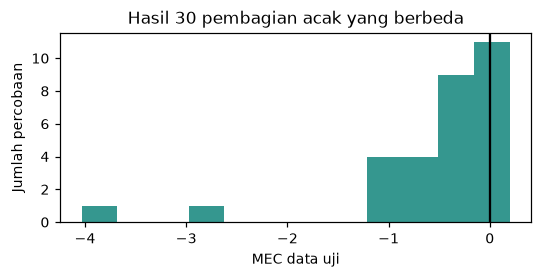

MEC terendah -4.03, median -0.37, tertinggi 0.20


In [7]:
hasil = []
for acak in range(30):
    a, b, c, d = train_test_split(tabel[numerik], y, test_size=.2, random_state=acak)
    m = RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1).fit(a, c)
    hasil.append(ukuran(d, m.predict(b))['MEC'])
plt.figure(figsize=(5, 2.6)); plt.hist(hasil, bins=12, color='#35978f'); plt.axvline(0, color='k')
plt.xlabel('MEC data uji'); plt.ylabel('Jumlah percobaan'); plt.title('Hasil 30 pembagian acak yang berbeda')
plt.tight_layout(); plt.savefig('hasil/sebaran_mec_pembagian_tunggal.png', dpi=150); plt.show()
print(f'MEC terendah {min(hasil):.2f}, median {np.median(hasil):.2f}, tertinggi {max(hasil):.2f}')

# Bagian B. Penyiapan dan pemilihan kovariat

## B1. Memetakan kovariat ke faktor SCORPAN

Isi tabel berikut mengikuti Tabel 8.1. Kolom terakhir adalah alasan pedologisnya untuk C-organik, yaitu kriteria pertama pemilihan kovariat. Alasan itu adalah hipotesis yang belum tentu terbukti pada data ini. Perhatikan faktor yang kosong: tidak ada data iklim karena hampir tidak bervariasi di wilayah sekecil ini, dan peta bahan induk belum tersedia.

In [8]:
faktor = pd.DataFrame([
    ('ndvi_2024', 'o', 'Sentinel-2', 'Vegetasi kemarau, masukan bahan organik'),
    ('ndvi_2025', 'o', 'Sentinel-2', 'Vegetasi kemarau, masukan bahan organik'),
    ('kat_penggunaan_lahan', 'o', 'Foto udara', 'Pengelolaan, pengolahan, dan masukan bahan organik'),
    ('twi', 'r', 'DEM GLO-30', 'Lokasi basah memperlambat dekomposisi'),
    ('lereng', 'r', 'DEM GLO-30', 'Erosi mengangkut lapisan atas'),
    ('tpi', 'r', 'DEM GLO-30', 'Punggungan kehilangan, lembah menerima material'),
    ('tri', 'r', 'DEM GLO-30', 'Kekasaran medan'),
    ('elevasi', 'r', 'DEM GLO-30', 'Posisi umum dalam lanskap'),
    ('arah_utara', 'r', 'DEM GLO-30', 'Arah hadap, penerimaan cahaya dan kelembapan'),
    ('jarak_sungai', 'r', 'Peta sungai', 'Kedekatan dengan alur dan endapan'),
    ('kat_bentuklahan', 'r/p', 'Peta riset', 'Proses geomorfologi dan bahan'),
    ('bsi_2024', 'o/s', 'Sentinel-2', 'Keterbukaan tanah'),
    ('bi_2024', 'o/s', 'Sentinel-2', 'Bahan organik menurunkan pantulan bila tanah terbuka'),
    ('cmr_2024', 'o/s', 'Sentinel-2', 'Rasio SWIR, peka terhadap sisa tanaman dan lempung'),
    ('sar_vv', 'o/r', 'Sentinel-1', 'Kekasaran dan kelembapan permukaan, bentuk medan'),
    ('sar_vh', 'o', 'Sentinel-1', 'Hamburan volume vegetasi'),
], columns=['Kovariat', 'Faktor', 'Sumber', 'Alasan'])
faktor

,Kovariat,Faktor,Sumber,Alasan
0,ndvi_2024,o,Sentinel-2,"Vegetasi kemarau, masukan bahan organik"
1,ndvi_2025,o,Sentinel-2,"Vegetasi kemarau, masukan bahan organik"
2,kat_penggunaan_lahan,o,Foto udara,"Pengelolaan, pengolahan, dan masukan bahan org..."
3,twi,r,DEM GLO-30,Lokasi basah memperlambat dekomposisi
4,lereng,r,DEM GLO-30,Erosi mengangkut lapisan atas
5,tpi,r,DEM GLO-30,"Punggungan kehilangan, lembah menerima material"
6,tri,r,DEM GLO-30,Kekasaran medan
7,elevasi,r,DEM GLO-30,Posisi umum dalam lanskap
8,arah_utara,r,DEM GLO-30,"Arah hadap, penerimaan cahaya dan kelembapan"
9,jarak_sungai,r,Peta sungai,Kedekatan dengan alur dan endapan


## B2. Membuang kovariat yang saling berkorelasi

Kovariat yang sangat mirip cukup diwakili salah satunya. Urutan pada daftar `prioritas` menyatakan penilaian pedologis untuk C-organik: masukan dari vegetasi dan kebasahan didahulukan, lalu erosi dan posisi lanskap. Kovariat di depan dipertahankan lebih dulu. Korelasi dihitung dari seluruh piksel di dalam Sub-DAS, bukan dari 50 titik saja, agar lebih stabil. Korelasi dengan nilai tanah sengaja **tidak** dipakai untuk memilih, karena dengan 50 titik cara itu mudah menangkap hubungan kebetulan.

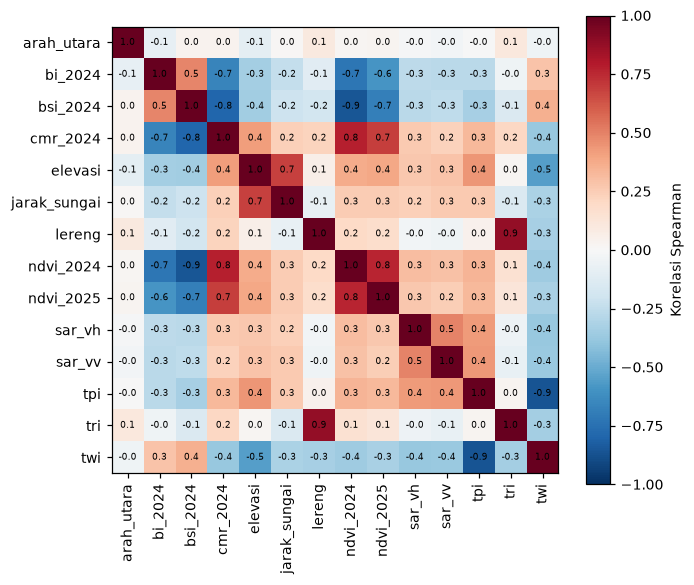

bsi_2024     dibuang: r = -0.86 dengan ndvi_2024
tpi          dibuang: r = -0.86 dengan twi
tri          dibuang: r = 0.88 dengan lereng
Terpilih: ['ndvi_2024', 'twi', 'lereng', 'jarak_sungai', 'elevasi', 'arah_utara', 'cmr_2024', 'sar_vv', 'sar_vh', 'bi_2024', 'ndvi_2025']


In [9]:
dalam = kubus[nama_kov.index('kat_bentuklahan')] > 0     # piksel di dalam Sub-DAS
piksel = pd.DataFrame(kubus[:, dalam].T, columns=nama_kov)
r_pix = piksel[numerik].corr(method='spearman')

fig, ax = plt.subplots(figsize=(6.4, 5.4))
g = ax.imshow(r_pix, cmap='RdBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(numerik)), numerik, rotation=90); ax.set_yticks(range(len(numerik)), numerik)
for i in range(len(numerik)):
    for j in range(len(numerik)):
        ax.text(j, i, f'{r_pix.iloc[i, j]:.1f}', ha='center', va='center', fontsize=6)
plt.colorbar(g, label='Korelasi Spearman'); plt.tight_layout(); plt.savefig('hasil/korelasi_kovariat.png', dpi=150); plt.show()

prioritas = ['ndvi_2024', 'twi', 'lereng', 'jarak_sungai', 'elevasi', 'arah_utara', 'cmr_2024', 'sar_vv', 'sar_vh', 'bi_2024', 'bsi_2024', 'ndvi_2025', 'tpi', 'tri']
AMBANG = 0.8
terpilih = []
for k in prioritas:
    if all(abs(r_pix.loc[k, t]) < AMBANG for t in terpilih):
        terpilih.append(k)
    else:
        lawan = max(terpilih, key=lambda t: abs(r_pix.loc[k, t]))
        print(f'{k:12s} dibuang: r = {r_pix.loc[k, lawan]:.2f} dengan {lawan}')
print('Terpilih:', terpilih)

## B3. Menambahkan kovariat kategorik

*Random forest* di scikit-learn memerlukan angka, sehingga kategori diubah menjadi kolom 0/1 (*one-hot*). Kolom untuk kelas yang tidak memiliki titik sampel tetap dibuat, karena model tetap harus memprediksi piksel kelas tersebut.

In [10]:
label_bl = {1: 'Interfluve', 2: 'Lereng Atas', 3: 'Lereng Tengah', 4: 'Lereng Bawah', 5: 'Lereng Kaki Koluvial', 6: 'Dataran Koluvial'}
label_pl = {1: 'Agroforestri', 2: 'Tegalan', 3: 'Sawah', 4: 'Permukiman'}

def siapkan_X(df):
    X = df[terpilih].copy()
    for k, v in label_bl.items():
        X['bl_' + v] = (df['kat_bentuklahan'].astype(int) == k).astype(float)
    for k, v in label_pl.items():
        X['pl_' + v] = (df['kat_penggunaan_lahan'].astype(int) == k).astype(float)
    return X

X = siapkan_X(tabel)
print('Jumlah titik per bentuklahan:', tabel['kat_bentuklahan'].astype(int).map(label_bl).value_counts().to_dict())
print('Jumlah titik per penggunaan lahan:', tabel['kat_penggunaan_lahan'].astype(int).map(label_pl).value_counts().to_dict())
print('Ukuran tabel pemodelan:', X.shape)
X.assign(**{SASARAN: y}).to_csv('hasil/tabel_pemodelan.csv', index=False)

Jumlah titik per bentuklahan: {'Lereng Tengah': 15, 'Lereng Bawah': 11, 'Lereng Atas': 10, 'Interfluve': 6, 'Lereng Kaki Koluvial': 5, 'Dataran Koluvial': 3}
Jumlah titik per penggunaan lahan: {'Agroforestri': 35, 'Sawah': 8, 'Tegalan': 7}
Ukuran tabel pemodelan: (50, 21)


# Bagian C. Pembangunan model DSM

## C1. Skema validasi

Dua skema dibandingkan. **Acak** membagi titik secara acak ke dalam lima kelompok. **Spasial** mengelompokkan titik yang berdekatan menjadi lima blok, lalu menyisihkan satu blok setiap putaran, sehingga data uji tidak punya tetangga dekat di data latih.

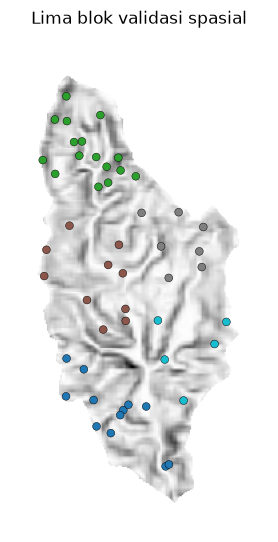

Jumlah titik per blok: [12 16 10  7  5]


In [11]:
blok = KMeans(n_clusters=5, n_init=10, random_state=0).fit_predict(sampel[['x', 'y']])
fig, ax = plt.subplots(figsize=(3.4, 5))
with rasterio.open('kovariat/lereng.tif') as r:
    ax.imshow(np.where(dalam, kubus[nama_kov.index('lereng')], np.nan), extent=[r.bounds.left, r.bounds.right, r.bounds.bottom, r.bounds.top], cmap='Greys')
ax.scatter(sampel.x, sampel.y, c=blok, cmap='tab10', s=26, edgecolor='k', lw=.3)
ax.set_title('Lima blok validasi spasial'); ax.axis('off')
plt.tight_layout(); plt.savefig('hasil/blok_validasi.png', dpi=150); plt.show()
print('Jumlah titik per blok:', np.bincount(blok))

## C2. Membandingkan model dengan pembanding yang paling sederhana

Model harus dibandingkan dengan sesuatu. Pembanding paling sederhana adalah **menebak rata-rata**, yaitu MEC mendekati 0. Pembanding kedua adalah **rata-rata per bentuklahan**, yang setara dengan peta tanah konvensional: setiap satuan peta diberi satu nilai. Jika model yang rumit tidak mengalahkan keduanya, kerumitan itu belum memberi manfaat.

In [12]:
class RataKelas:
    """Memprediksi rata-rata per kelas bentuklahan, seperti satuan pada peta tanah."""
    def fit(self, X, y):
        kolom = [c for c in X.columns if c.startswith('bl_')]
        self.kolom, self.umum = kolom, y.mean()
        self.nilai = {c: y[X[c].values == 1].mean() if (X[c].values == 1).any() else y.mean() for c in kolom}
        return self
    def predict(self, X):
        p = np.full(len(X), self.umum)
        for c in self.kolom:
            p[X[c].values == 1] = self.nilai[c]
        return p

class RataUmum:
    def fit(self, X, y):
        self.n = y.mean(); return self
    def predict(self, X):
        return np.full(len(X), self.n)

def model_baru(nama):
    if nama == 'Menebak rata-rata': return RataUmum()
    if nama == 'Rata-rata per bentuklahan': return RataKelas()
    if nama == 'Regresi linear': return make_pipeline(StandardScaler(), LinearRegression())
    return RandomForestRegressor(n_estimators=500, min_samples_leaf=3, max_features=.5, random_state=0, n_jobs=-1)

def validasi(nama, X, y, iris):
    p = np.zeros(len(y))
    for latih, uji in iris:
        p[uji] = model_baru(nama).fit(X.iloc[latih], y[latih]).predict(X.iloc[uji])
    return p

iris_acak = list(KFold(5, shuffle=True, random_state=0).split(X))
iris_spasial = list(GroupKFold(5).split(X, groups=blok))
baris = []
for nama in ['Menebak rata-rata', 'Rata-rata per bentuklahan', 'Regresi linear', 'Random forest']:
    for skema, iris in [('Acak', iris_acak), ('Spasial', iris_spasial)]:
        u = ukuran(y, validasi(nama, X, y, iris))
        if nama == 'Menebak rata-rata':
            u['R2'] = np.nan      # prediksi hampir konstan, korelasinya tidak bermakna
        baris.append({'Model': nama, 'Validasi': skema, **u})
metrik = pd.DataFrame(baris).round(2)
metrik.to_csv(f'hasil/metrik_validasi_{SASARAN}.csv', index=False)
metrik

,Model,Validasi,ME,MAE,RMSE,MEC,R2
0,Menebak rata-rata,Acak,-0.00,0.32,0.41,-0.02,NaN
1,Menebak rata-rata,Spasial,0.01,0.32,0.41,-0.03,NaN
2,Rata-rata per bentuklahan,Acak,0.00,0.34,0.43,-0.12,0.00
3,Rata-rata per bentuklahan,Spasial,0.01,0.35,0.46,-0.28,0.00
4,Regresi linear,Acak,0.01,0.38,0.49,-0.46,0.06
5,Regresi linear,Spasial,-0.10,0.40,0.56,-0.93,0.06
6,Random forest,Acak,0.00,0.32,0.41,-0.02,0.01
7,Random forest,Spasial,0.01,0.33,0.43,-0.13,0.00


**Cara membaca.** MEC di bawah 0 berarti prediksi lebih buruk daripada menebak rata-rata. Baris "Menebak rata-rata" sedikit di bawah nol karena setiap putaran memakai rata-rata data latihnya, bukan rata-rata seluruh titik; itulah patokan yang harus dilampaui. Kolom R² tidak peka terhadap bias (Tabel 8.3), sehingga jangan membacanya sendirian.

## C3. Apakah sifat tanah lain lebih mudah diprediksi?

In [13]:
baris = []
for t in ['C_Organik_1', 'C_Organik_2', 'Lempung_1', 'Lempung_2', 'Pasir_1', 'Debu_1', 'pH_H2O_1']:
    yt = sampel[t].values
    pa = validasi('Random forest', X, yt, iris_acak)
    ps = validasi('Random forest', X, yt, iris_spasial)
    pk = validasi('Rata-rata per bentuklahan', X, yt, iris_spasial)
    baris.append({'Sifat': t, 'Rerata': yt.mean(), 'SD': yt.std(ddof=1), 'RMSE spasial': ukuran(yt, ps)['RMSE'],
                  'MEC RF acak': ukuran(yt, pa)['MEC'], 'MEC RF spasial': ukuran(yt, ps)['MEC'], 'MEC per bentuklahan': ukuran(yt, pk)['MEC']})
semua = pd.DataFrame(baris).round(2)
semua.to_csv('hasil/metrik_semua_sifat.csv', index=False)
semua

,Sifat,Rerata,SD,RMSE spasial,MEC RF acak,MEC RF spasial,MEC per bentuklahan
0,C_Organik_1,1.14,0.41,0.43,-0.02,-0.13,-0.28
1,C_Organik_2,0.93,0.30,0.30,-0.01,-0.01,-0.18
2,Lempung_1,62.48,9.82,10.92,-0.23,-0.26,-0.28
3,Lempung_2,64.78,10.32,10.96,-0.08,-0.15,-0.12
4,Pasir_1,16.43,6.81,7.73,-0.21,-0.32,-0.23
5,Debu_1,21.09,6.56,6.54,-0.05,-0.01,-0.29
6,pH_H2O_1,5.20,0.36,0.39,-0.21,-0.20,-0.16


## C4. Kovariat apa yang dipakai model, dan bolehkah dipercaya?

Tingkat kepentingan dihitung dengan permutasi pada data di luar blok latih. Jika MEC model mendekati atau di bawah nol, urutan ini tidak boleh ditafsirkan sebagai temuan pedologis: model yang tidak mampu memprediksi tidak dapat memberi tahu apa yang mengendalikan tanah (Wadoux, Samuel-Rosa, et al., 2020).

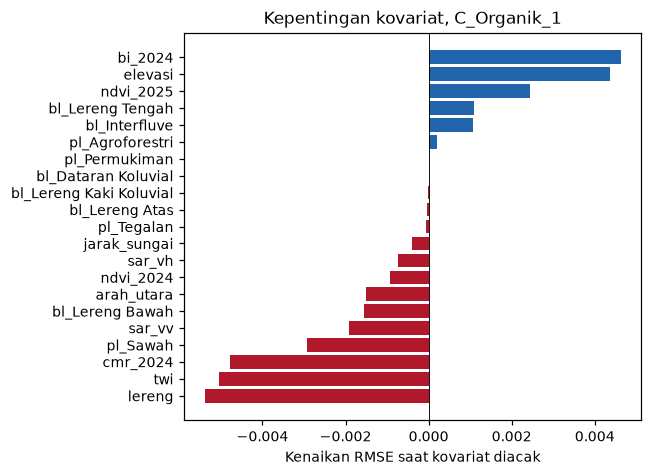

In [14]:
pent = []
for latih, uji in iris_spasial:
    m = model_baru('Random forest').fit(X.iloc[latih], y[latih])
    pent.append(permutation_importance(m, X.iloc[uji], y[uji], n_repeats=20, random_state=0, scoring='neg_root_mean_squared_error').importances_mean)
pent = pd.Series(np.mean(pent, axis=0), index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(6, 4.4))
ax.barh(pent.index, pent.values, color=['#b2182b' if v < 0 else '#2166ac' for v in pent.values])
ax.axvline(0, color='k', lw=.6); ax.set(xlabel='Kenaikan RMSE saat kovariat diacak', title=f'Kepentingan kovariat, {SASARAN}')
plt.tight_layout(); plt.savefig('hasil/kepentingan_kovariat.png', dpi=150); plt.show()

## C5. Model akhir dan peta prediksi

Model akhir dilatih dengan semua titik memakai *quantile regression forest* (QRF), sehingga setiap piksel memperoleh median dan interval prediksi 90%. Peta ini tetap dibuat meskipun validasinya lemah, karena tujuan latihan adalah menguasai alur kerja dan belajar membacanya secara kritis.

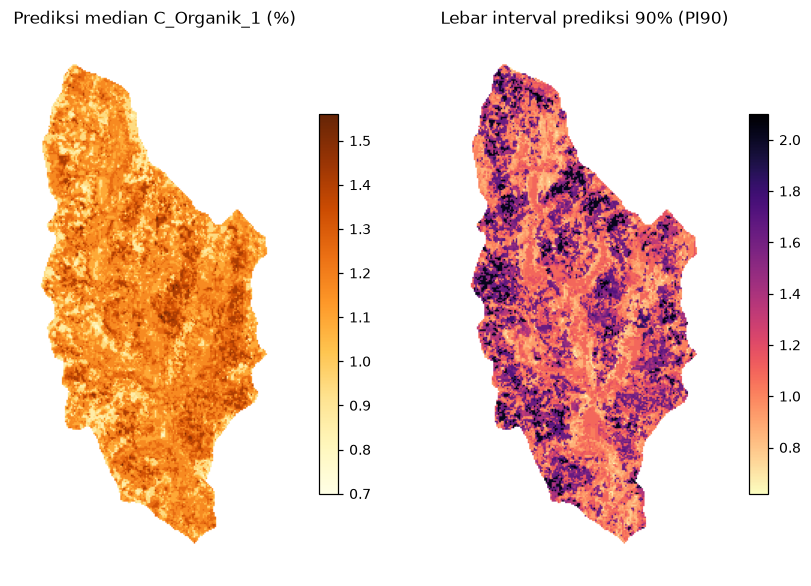

Rentang pengamatan 0.16-2.26 | rentang prediksi median 0.70-1.56 | PI90 rata-rata 1.26


In [15]:
qrf = RandomForestQuantileRegressor(n_estimators=500, min_samples_leaf=3, max_features=.5, random_state=0, n_jobs=-1)
qrf.fit(X, y)
X_piksel = siapkan_X(piksel)[X.columns]
q = qrf.predict(X_piksel, quantiles=[.05, .5, .95])

def ke_peta(nilai):
    peta = np.full((tinggi, lebar), np.nan, dtype='float32')
    peta[dalam] = nilai
    return peta

def simpan(peta, nama):
    with rasterio.open(f'hasil/{nama}.tif', 'w', driver='GTiff', height=tinggi, width=lebar, count=1, dtype='float32', crs=crs, transform=transform, nodata=-9999, compress='deflate') as d:
        d.write(np.where(np.isnan(peta), -9999, peta), 1)

peta_median, peta_pi90 = ke_peta(q[:, 1]), ke_peta(q[:, 2] - q[:, 0])
simpan(peta_median, f'prediksi_{SASARAN}')
simpan(peta_pi90, f'pi90_{SASARAN}')

fig, ax = plt.subplots(1, 2, figsize=(8, 5.4))
a = ax[0].imshow(peta_median, cmap='YlOrBr'); ax[0].set_title(f'Prediksi median {SASARAN} (%)'); plt.colorbar(a, ax=ax[0], shrink=.7)
b = ax[1].imshow(peta_pi90, cmap='magma_r'); ax[1].set_title('Lebar interval prediksi 90% (PI90)'); plt.colorbar(b, ax=ax[1], shrink=.7)
for x in ax: x.axis('off')
plt.tight_layout(); plt.savefig('hasil/peta_prediksi_dan_pi90.png', dpi=150); plt.show()
print(f'Rentang pengamatan {y.min():.2f}-{y.max():.2f} | rentang prediksi median {np.nanmin(peta_median):.2f}-{np.nanmax(peta_median):.2f} | PI90 rata-rata {np.nanmean(peta_pi90):.2f}')

Bandingkan rentang prediksi dengan rentang pengamatan yang dicetak di atas. *Random forest* merata-ratakan banyak pohon, sehingga petanya cenderung lebih sempit dan lebih halus daripada keragaman tanah yang sebenarnya.

## C6. Menilai interval prediksi dengan PICP

Jika interval 90% itu jujur, sekitar 90% titik uji seharusnya berada di dalamnya.

In [16]:
def picp(iris):
    masuk = np.zeros(len(y), bool)
    for latih, uji in iris:
        m = RandomForestQuantileRegressor(n_estimators=300, min_samples_leaf=3, max_features=.5, random_state=0, n_jobs=-1).fit(X.iloc[latih], y[latih])
        qq = m.predict(X.iloc[uji], quantiles=[.05, .95])
        masuk[uji] = (y[uji] >= qq[:, 0]) & (y[uji] <= qq[:, 1])
    return masuk.mean()

print(f'PICP validasi acak   : {picp(iris_acak):.2f}')
print(f'PICP validasi spasial: {picp(iris_spasial):.2f}')

PICP validasi acak   : 0.86


PICP validasi spasial: 0.82


## C7. Wilayah keberlakuan model

Indeks ketidakmiripan (DI) mengukur jarak setiap piksel ke titik latih terdekat dalam ruang kovariat. Meyer dan Pebesma (2021) membobot jarak ini dengan tingkat kepentingan kovariat. Karena tingkat kepentingan pada Bagian C4 tidak dapat dipercaya, di sini semua kovariat numerik diberi bobot sama. Ambangnya diturunkan dari DI titik latih saat titik-titik dari blok yang sama disisihkan. Ini penerapan sederhana untuk peragaan.

Ambang DI 0.76 | 93.5% piksel berada di dalam wilayah keberlakuan


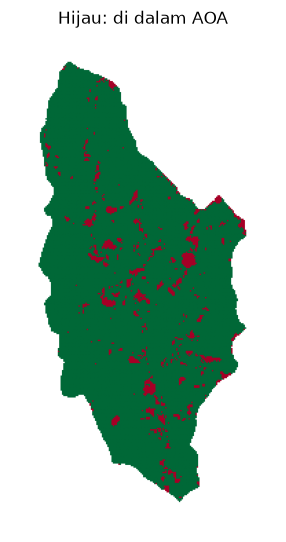

In [17]:
skala = StandardScaler().fit(X[terpilih])
Zt, Zp = skala.transform(X[terpilih]), skala.transform(X_piksel[terpilih])
jarak_latih = NearestNeighbors(n_neighbors=len(Zt)).fit(Zt).kneighbors(Zt)[0][:, 1:]
d_rata = jarak_latih.mean()
di_titik = np.array([np.linalg.norm(Zt[blok != blok[i]] - Zt[i], axis=1).min() for i in range(len(Zt))]) / d_rata
ambang = np.percentile(di_titik, 75) + 1.5 * (np.percentile(di_titik, 75) - np.percentile(di_titik, 25))
di_piksel = NearestNeighbors(n_neighbors=1).fit(Zt).kneighbors(Zp)[0].ravel() / d_rata
aoa = (di_piksel <= ambang).astype('float32')
simpan(ke_peta(di_piksel), f'di_{SASARAN}')
simpan(ke_peta(aoa), f'aoa_{SASARAN}')
print(f'Ambang DI {ambang:.2f} | {100 * aoa.mean():.1f}% piksel berada di dalam wilayah keberlakuan')
plt.figure(figsize=(3.8, 5)); plt.imshow(ke_peta(aoa), cmap='RdYlGn', vmin=0, vmax=1); plt.axis('off'); plt.title('Hijau: di dalam AOA')
plt.tight_layout(); plt.savefig('hasil/aoa.png', dpi=150); plt.show()

## C8. Melihat residual

Residual yang masih berkelompok menandakan ada proses yang belum tertangkap kovariat. Moran's I dihitung dari residual validasi spasial dengan bobot kebalikan jarak. Nilai mendekati 0 berarti residual tidak berpola.

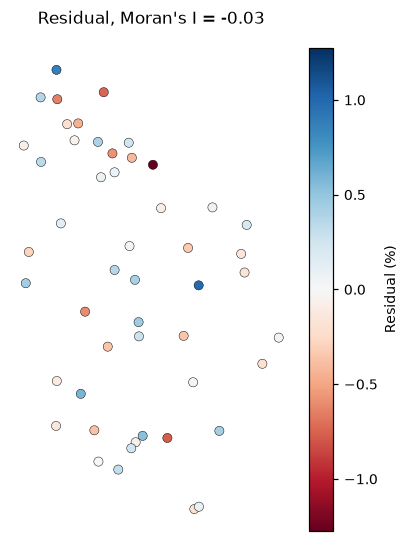

In [18]:
res = y - validasi('Random forest', X, y, iris_spasial)
xy = sampel[['x', 'y']].values
D = np.hypot(*(xy[:, None, :] - xy[None, :, :]).transpose(2, 0, 1))
W = np.where(D > 0, 1 / np.where(D == 0, 1, D), 0)
z = res - res.mean()
moran = len(z) / W.sum() * (W * np.outer(z, z)).sum() / (z ** 2).sum()
fig, ax = plt.subplots(figsize=(3.8, 5))
batas = np.abs(res).max()
g = ax.scatter(xy[:, 0], xy[:, 1], c=res, cmap='RdBu', vmin=-batas, vmax=batas, s=36, edgecolor='k', lw=.3)
plt.colorbar(g, label='Residual (%)'); ax.set_title(f"Residual, Moran's I = {moran:.2f}"); ax.axis('off')
plt.tight_layout(); plt.savefig('hasil/residual.png', dpi=150); plt.show()
pd.DataFrame({'Titik': sampel['Titik'], 'x': sampel.x, 'y': sampel.y, 'residual': res.round(2)}).to_csv(f'hasil/residual_{SASARAN}.csv', index=False)

## Yang dibawa ke QGIS dan ke presentasi

Folder `hasil/` kini berisi peta prediksi, PI90, DI, AOA, tabel metrik, dan gambar. Buka GeoTIFF-nya di QGIS (Modul Praktik 5, tahap terakhir), tumpangkan dengan peta SMU dari Praktik 2, lalu siapkan jawaban untuk tiga pertanyaan berikut:

1. Seberapa baik model ini dibandingkan pembanding sederhananya?
2. Di mana peta ini paling tidak bisa dipercaya?
3. Data apa yang paling mungkin memperbaiki hasilnya: titik sampel tambahan, DEM yang lebih rinci, atau peta bahan induk?